# Deforestation Tracking

Classify each Sentinel-2 pixel as **forest** or **non-forest**, then compare the yearly maps to measure forest loss.

## Setup

Imports and settings. Paths point at the training chips (`data/tiles/`) and the yearly images (`data/hf/composites/`).

In [1]:
import glob, os, time
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from pathlib import Path

# Find the project folder whether we run from the repo root or from notebooks/
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
TILES = ROOT / "data" / "tiles"                    # the 484 training chips
COMPOSITES = ROOT / "data" / "hf" / "composites"   # the 4 yearly images
YEARS = [2019, 2021, 2023, 2025]

BANDS = ["B02", "B03", "B04", "B08", "B11", "B12", "NDVI", "NBR", "NDWI"]
CLASSES = {0: "non-forest", 1: "forest"}           # binary task
CLASS_COLORS = {0: (0.6, 0.6, 0.6), 1: (0.14, 0.55, 0.24), 2: (0.86, 0.16, 0.16)}

# Speed knobs - a class project does not need all 22 million pixels to work.
N_TRAIN_PIXELS = 1_000_000
N_TEST_PIXELS = 300_000
N_TREES = 60
DOWNSAMPLE = 2      # read the yearly images at half size so this runs in ~1 minute

print("chips:", {s: len(glob.glob(str(TILES / s / "2021" / "*.npz")))
                 for s in ("train", "val", "test")})

chips: {'train': 340, 'val': 72, 'test': 72}


## Step 1 - Look at the training data

Each chip is a 256x256 picture with 9 channels, plus a label map (0 = non-forest, 1 = forest, 2 = deforested).

In [2]:
def load_chip(path):
    d = np.load(path)
    return d["img"], d["mask"]      # img (9,256,256) float32, mask (256,256) uint8

train_files = sorted(glob.glob(str(TILES / "train" / "2021" / "*.npz")))
img, mask = load_chip(train_files[0])
print("image:", img.shape, "->", len(BANDS), "channels:", BANDS)
print("label:", mask.shape, "-> values:", np.unique(mask))

image: (9, 256, 256) -> 9 channels: ['B02', 'B03', 'B04', 'B08', 'B11', 'B12', 'NDVI', 'NBR', 'NDWI']
label: (256, 256) -> values: [0 1 2]


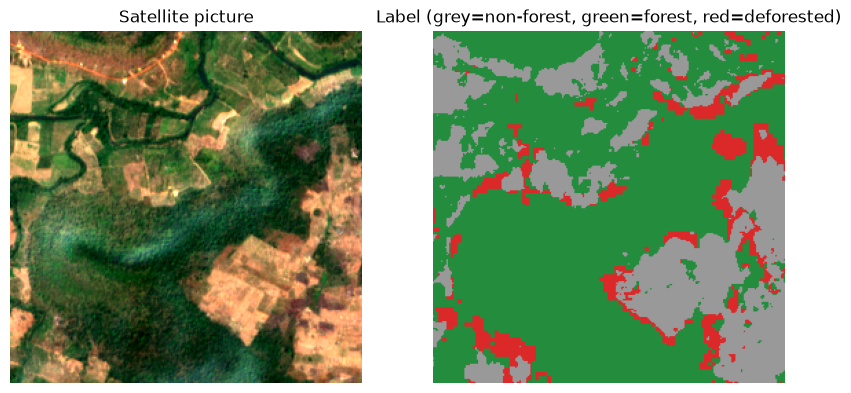

In [3]:
# Pick a chip that contains some 'deforested' pixels so we can see all 3 label values.
for f in train_files:
    _, m = load_chip(f)
    if (m == 2).mean() > 0.05:
        img, mask = load_chip(f)
        break

def true_colour(img):               # B04, B03, B02 = red, green, blue
    rgb = np.stack([img[2], img[1], img[0]], axis=-1)
    lo, hi = np.percentile(rgb, (2, 98))
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

def colour_mask(mask):
    out = np.zeros((*mask.shape, 3))
    for k, c in CLASS_COLORS.items():
        out[mask == k] = c
    return out

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(true_colour(img)); ax[0].set_title("Satellite picture")
ax[1].imshow(colour_mask(mask)); ax[1].set_title("Label (grey=non-forest, green=forest, red=deforested)")
for a in ax:
    a.axis("off")
plt.show()

## Step 2 - Turn the pixels into a table

Each pixel becomes one row of 9 channel values. We train on **forest (1)** vs **non-forest (0)** and skip the ambiguous `deforested` pixels.

In [4]:
rng = np.random.default_rng(0)

def pixels_from(split, n):
    xs, ys = [], []
    files = sorted(glob.glob(str(TILES / split / "2021" / "*.npz")))
    per = max(1, n // len(files))
    for f in files:
        img, mask = load_chip(f)
        x = np.moveaxis(img, 0, -1).reshape(-1, 9)   # (pixels, 9)
        y = mask.reshape(-1)
        keep = y != 2                                # ignore the ambiguous class
        x, y = x[keep], y[keep]                      # now y is only 0 or 1
        if x.shape[0] > per:
            idx = rng.choice(x.shape[0], per, replace=False)
            x, y = x[idx], y[idx]
        xs.append(x); ys.append(y)
    return np.concatenate(xs), np.concatenate(ys)

X_train, y_train = pixels_from("train", N_TRAIN_PIXELS)
X_test, y_test = pixels_from("test", N_TEST_PIXELS)
print("training table:", X_train.shape, "(rows = pixels, columns = channels)")
print("pixels per class:", {CLASSES[k]: int(v) for k, v in zip(*np.unique(y_train, return_counts=True))})

training table: (999940, 9) (rows = pixels, columns = channels)
pixels per class: {'non-forest': 94069, 'forest': 905871}


## Step 3 - Train the model

A Random Forest learns the forest / non-forest pattern from the labelled pixels.

In [5]:
model = RandomForestClassifier(n_estimators=N_TREES, class_weight="balanced",
                               n_jobs=-1, random_state=42)
t = time.time()
model.fit(X_train, y_train)
print(f"trained in {time.time() - t:.0f}s")

trained in 44s


## Step 4 - Evaluate

Tested on chips the model has never seen. IoU and F1 per class.

In [6]:
pred = model.predict(X_test)
cm = confusion_matrix(y_test, pred, labels=[0, 1])
print("Confusion matrix (rows = truth, columns = prediction):")
print(pd.DataFrame(cm, index=[CLASSES[i] for i in (0, 1)],
                       columns=[CLASSES[i] for i in (0, 1)]))

tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
iou = tp / np.maximum(tp + fp + fn, 1)
f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)

print("\nPer-class scores:")
for i in (0, 1):
    print(f"  {CLASSES[i]:>11}: IoU {iou[i]:.2f}   F1 {f1[i]:.2f}")
print(f"\nOverall accuracy: {(pred == y_test).mean():.3f}")

Confusion matrix (rows = truth, columns = prediction):
            non-forest  forest
non-forest        9585    1801
forest            3609  284957

Per-class scores:
   non-forest: IoU 0.64   F1 0.78
       forest: IoU 0.98   F1 0.99

Overall accuracy: 0.982


## Step 5 - Predict each year

Run the trained model on the four yearly images to get a forest map and forest area for each year.

In [7]:
HA_PER_PIXEL = (10 * DOWNSAMPLE) ** 2 / 10_000

def predict_year(year):
    with rasterio.open(str(COMPOSITES / f"s2_{year}.tif")) as src:
        h, w = src.height // DOWNSAMPLE, src.width // DOWNSAMPLE
        block = src.read(out_shape=(9, h, w))
    x = np.moveaxis(block, 0, -1).reshape(-1, 9)
    valid = np.isfinite(x).all(axis=1)
    cls = np.full(x.shape[0], -1, dtype="int16")
    cls[valid] = model.predict(x[valid])
    return (cls == 1).reshape(h, w), valid.reshape(h, w)

masks, valids = {}, {}
for y in YEARS:
    masks[y], valids[y] = predict_year(y)
    print(f"{y}: {masks[y].sum() * HA_PER_PIXEL:>10,.0f} ha forest")

2019:     77,867 ha forest


2021:     81,118 ha forest


2023:     80,609 ha forest


2025:     78,909 ha forest


## Step 6 - Forest loss per interval

Compare years: a pixel that is forest in A but not in B counts as loss.

2019 -> 2021: lost     1,358 ha
2021 -> 2023: lost     2,441 ha
2023 -> 2025: lost     3,092 ha


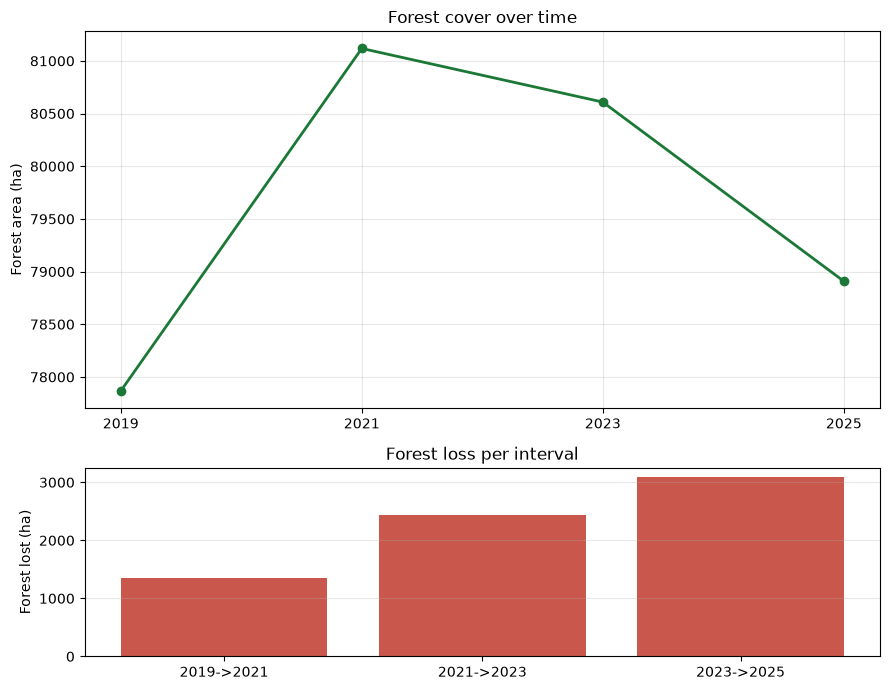

In [8]:
forest_ha = [masks[y].sum() * HA_PER_PIXEL for y in YEARS]
intervals, loss_ha = [], []
for a, b in zip(YEARS, YEARS[1:]):
    both = valids[a] & valids[b]
    loss = masks[a] & both & ~masks[b]          # forest in A, not forest in B
    intervals.append(f"{a}->{b}")
    loss_ha.append(loss.sum() * HA_PER_PIXEL)
    print(f"{a} -> {b}: lost {loss_ha[-1]:>9,.0f} ha")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), height_ratios=[2, 1])
ax1.plot(YEARS, forest_ha, "-o", color="#1b7837", linewidth=2)
ax1.set_ylabel("Forest area (ha)"); ax1.set_title("Forest cover over time")
ax1.set_xticks(YEARS); ax1.grid(alpha=0.3)
ax2.bar(intervals, loss_ha, color="#c0392b", alpha=0.85)
ax2.set_ylabel("Forest lost (ha)"); ax2.set_title("Forest loss per interval")
ax2.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

## Step 7 - Where the loss happened

Overlay the loss pixels on the NDVI image.

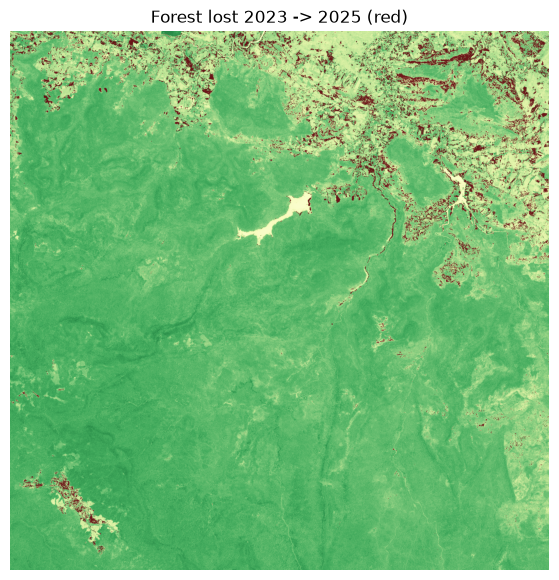

In [9]:
a, b = 2023, 2025
both = valids[a] & valids[b]
loss = masks[a] & both & ~masks[b]
with rasterio.open(str(COMPOSITES / f"s2_{a}.tif")) as src:
    h, w = src.height // DOWNSAMPLE, src.width // DOWNSAMPLE
    ndvi = src.read(7, out_shape=(h, w))

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(ndvi, cmap="YlGn", vmin=-0.1, vmax=0.9)
ax.imshow(np.ma.masked_where(~loss, loss.astype(float)), cmap="Reds",
          vmin=0, vmax=1, alpha=0.9)
ax.set_title(f"Forest lost {a} -> {b} (red)")
ax.axis("off")
plt.show()

## Step 8 - Save the results

Write the tables and images to `outputs/` for the dashboard.

In [10]:
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

pd.DataFrame({"year": YEARS,
              "forest_ha": [round(v, 1) for v in forest_ha]}).to_csv(
    OUT / "forest_area.csv", index=False)
pd.DataFrame({"interval": intervals,
              "loss_ha": [round(v, 1) for v in loss_ha]}).to_csv(
    OUT / "forest_loss.csv", index=False)

fig.savefig(OUT / "forest_timeline.png", dpi=110)
for a, b in zip(YEARS, YEARS[1:]):
    both = valids[a] & valids[b]
    loss = masks[a] & both & ~masks[b]
    with rasterio.open(str(COMPOSITES / f"s2_{a}.tif")) as src:
        h, w = src.height // DOWNSAMPLE, src.width // DOWNSAMPLE
        ndvi = src.read(7, out_shape=(h, w))
    fig2, ax2 = plt.subplots(figsize=(6, 6))
    ax2.imshow(ndvi, cmap="YlGn", vmin=-0.1, vmax=0.9)
    ax2.imshow(np.ma.masked_where(~loss, loss.astype(float)), cmap="Reds",
               vmin=0, vmax=1, alpha=0.9)
    ax2.set_title(f"Forest lost {a}->{b} (red)")
    ax2.axis("off")
    fig2.savefig(OUT / f"overlay_{a}_{b}.png", dpi=110)
    plt.close(fig2)

print("saved results to", OUT)

saved results to C:\Users\brath\OneDrive\Documents\Aupp\ML\deforestation_tracking\outputs
